In [5]:
import numpy as np
import pandas as pd
import random
import os

random.seed(42)
np.random.seed(42)

OUTPUT_DIR="manhole_model_output"

os.makedirs(OUTPUT_DIR,exist_ok=True)

In [6]:
N_NORMAL=3000
N_FLOOD=1500
N_BLOCKAGE=1500

In [7]:
def generate_normal(n):

    rows=[]

    for _ in range(n):

        # ---------------------------
        # Weather
        # ---------------------------

        rain_probability=np.random.uniform(0,40)

        precipitationIntensity=max(
            0,
            rain_probability*0.08+
            np.random.normal(0,1)
        )

        precipitationIntensity_next=max(
            0,
            precipitationIntensity+
            np.random.normal(0,1)
        )

        # ---------------------------
        # Water Dynamics
        # ---------------------------

        rise_rate1=max(
            0,
            precipitationIntensity*0.20+
            np.random.uniform(0,1)
        )

        rise_rate2=max(
            0,
            rise_rate1+
            np.random.uniform(-0.3,0.3)
        )

        # ---------------------------
        # Water Levels
        # ---------------------------

        base_level=np.random.uniform(2,12)

        water_level1=base_level+rise_rate1*np.random.uniform(0.2,0.5)

        water_level2=water_level1+np.random.uniform(-1.5,1.5)

        water_level2=np.clip(water_level2,1,15)

        level_difference=water_level1-water_level2

        rows.append([

            water_level1,
            water_level2,
            level_difference,
            rise_rate1,
            rise_rate2,
            precipitationIntensity,
            rain_probability,
            precipitationIntensity_next,
            "normal"

        ])

    return pd.DataFrame(rows,columns=[

        "water_level_node1",
        "water_level_node2",
        "level_diff",
        "rise_rate_node1",
        "rise_rate_node2",
        "precipitationIntensity",
        "precipitationProbability",
        "precipitationIntensity_next_hour",
        "label"

    ])

In [8]:
def generate_flood(n):

    rows=[]

    for _ in range(n):

        rain_probability=np.random.uniform(75,100)

        precipitationIntensity=np.random.uniform(25,80)

        precipitationIntensity_next=np.clip(

            precipitationIntensity+
            np.random.uniform(-5,20),

            20,
            100

        )

        rise_rate1=precipitationIntensity*0.25+np.random.uniform(2,6)

        rise_rate2=rise_rate1+np.random.uniform(-1,1)

        water_level1=np.clip(

            15+
            rise_rate1+
            np.random.uniform(0,8),

            18,
            35

        )

        water_level2=np.clip(

            water_level1+
            np.random.uniform(-2,2),

            18,
            35

        )

        level_difference=water_level1-water_level2

        rows.append([

            water_level1,
            water_level2,
            level_difference,
            rise_rate1,
            rise_rate2,
            precipitationIntensity,
            rain_probability,
            precipitationIntensity_next,
            "flood"

        ])

    return pd.DataFrame(rows,columns=[

        "water_level_node1",
        "water_level_node2",
        "level_diff",
        "rise_rate_node1",
        "rise_rate_node2",
        "precipitationIntensity",
        "precipitationProbability",
        "precipitationIntensity_next_hour",
        "label"

    ])

In [9]:
def generate_blockage(n):

    rows=[]

    for _ in range(n):

        rain_probability=np.random.uniform(0,100)

        precipitationIntensity=np.random.uniform(0,40)

        precipitationIntensity_next=max(

            0,

            precipitationIntensity+

            np.random.uniform(-5,10)

        )

        rise_rate1=np.random.uniform(8,18)

        rise_rate2=np.random.uniform(-0.5,1.5)

        water_level1=np.random.uniform(22,35)

        blockage_factor=np.random.uniform(12,28)

        water_level2=max(

            1,

            water_level1-

            blockage_factor

        )

        level_difference=water_level1-water_level2

        rows.append([

            water_level1,
            water_level2,
            level_difference,
            rise_rate1,
            rise_rate2,
            precipitationIntensity,
            rain_probability,
            precipitationIntensity_next,
            "blockage"

        ])

    return pd.DataFrame(rows,columns=[

        "water_level_node1",
        "water_level_node2",
        "level_diff",
        "rise_rate_node1",
        "rise_rate_node2",
        "precipitationIntensity",
        "precipitationProbability",
        "precipitationIntensity_next_hour",
        "label"

    ])

In [10]:
df=pd.concat([

    generate_normal(N_NORMAL),

    generate_flood(N_FLOOD),

    generate_blockage(N_BLOCKAGE)

],ignore_index=True)

numeric=df.select_dtypes(include=np.number).columns

for col in numeric:

    df[col]+=np.random.normal(

        0,

        0.2,

        len(df)

    )

df=df.sample(

    frac=1,

    random_state=42

).reset_index(drop=True)

df.to_csv(

    os.path.join(

        OUTPUT_DIR,

        "dataset.csv"

    ),

    index=False

)

print(df.head())

print()

print(df.label.value_counts())

   water_level_node1  water_level_node2  level_diff  rise_rate_node1  \
0          10.424745           9.750400    1.162034         0.507440   
1          31.844330          30.379991    1.476630        12.142430   
2           2.479552           1.417590    1.063849         0.563763   
3           6.517663           7.867494   -1.753115         1.272552   
4          29.834402          11.101781   18.935566        10.007675   

   rise_rate_node2  precipitationIntensity  precipitationProbability  \
0        -0.086671                2.032448                 33.916690   
1        11.695644               36.883755                 85.410644   
2         0.325692                1.670630                 14.530161   
3         0.907798                2.966702                 23.813932   
4         1.529917                2.636598                 95.374595   

   precipitationIntensity_next_hour     label  
0                          2.368889    normal  
1                         41.249605   

In [11]:
def generate_cloudburst(n):

    rows=[]

    for _ in range(n):

        rain_probability=np.random.uniform(95,100)

        precipitationIntensity=np.random.uniform(60,120)

        precipitationIntensity_next=np.random.uniform(50,100)

        rise_rate1=np.random.uniform(15,25)

        rise_rate2=np.random.uniform(14,24)

        water_level1=np.random.uniform(28,35)

        water_level2=np.clip(

            water_level1+
            np.random.uniform(-1,1),

            26,
            35

        )

        level_diff=water_level1-water_level2

        rows.append([

            water_level1,
            water_level2,
            level_diff,
            rise_rate1,
            rise_rate2,
            precipitationIntensity,
            rain_probability,
            precipitationIntensity_next,
            "flood"

        ])

    return pd.DataFrame(rows,columns=df.columns)

In [12]:
def generate_partial_blockage(n):

    rows=[]

    for _ in range(n):

        rain_probability=np.random.uniform(20,90)

        precipitationIntensity=np.random.uniform(5,35)

        precipitationIntensity_next=np.random.uniform(5,40)

        rise_rate1=np.random.uniform(5,12)

        rise_rate2=np.random.uniform(2,6)

        water_level1=np.random.uniform(18,32)

        blockage=np.random.uniform(5,12)

        water_level2=water_level1-blockage

        level_diff=water_level1-water_level2

        rows.append([

            water_level1,
            water_level2,
            level_diff,
            rise_rate1,
            rise_rate2,
            precipitationIntensity,
            rain_probability,
            precipitationIntensity_next,
            "blockage"

        ])

    return pd.DataFrame(rows,columns=df.columns)

In [13]:
def generate_draining(n):

    rows=[]

    for _ in range(n):

        rain_probability=np.random.uniform(0,15)

        precipitationIntensity=0

        precipitationIntensity_next=0

        rise_rate1=np.random.uniform(-2,0)

        rise_rate2=np.random.uniform(-2,0)

        water_level1=np.random.uniform(10,22)

        water_level2=water_level1+np.random.uniform(-2,2)

        level_diff=water_level1-water_level2

        rows.append([

            water_level1,
            water_level2,
            level_diff,
            rise_rate1,
            rise_rate2,
            precipitationIntensity,
            rain_probability,
            precipitationIntensity_next,
            "normal"

        ])

    return pd.DataFrame(rows,columns=df.columns)

In [14]:
extra=pd.concat([

    generate_cloudburst(400),

    generate_partial_blockage(500),

    generate_draining(400)

],ignore_index=True)

df=pd.concat([

    df,

    extra

],ignore_index=True)

print(df.label.value_counts())

label
normal      3400
blockage    2000
flood       1900
Name: count, dtype: int64


In [15]:
numeric=df.select_dtypes(include=np.number).columns

for col in numeric:

    df[col]+=np.random.normal(

        0,

        0.15,

        len(df)

    )

In [16]:
fault_rows=np.random.choice(

    df.index,

    int(len(df)*0.01),

    replace=False

)

for r in fault_rows:

    feature=np.random.choice([

        "water_level_node1",

        "water_level_node2",

        "rise_rate_node1",

        "rise_rate_node2"

    ])

    df.loc[r,feature]+=np.random.uniform(-4,4)

In [17]:
df["water_level_node1"]=df["water_level_node1"].clip(0,35)

df["water_level_node2"]=df["water_level_node2"].clip(0,35)

df["rise_rate_node1"]=df["rise_rate_node1"].clip(-2,25)

df["rise_rate_node2"]=df["rise_rate_node2"].clip(-2,25)

df["precipitationIntensity"]=df["precipitationIntensity"].clip(0,120)

df["precipitationProbability"]=df["precipitationProbability"].clip(0,100)

df["precipitationIntensity_next_hour"]=df["precipitationIntensity_next_hour"].clip(0,120)

df["level_diff"]=df["water_level_node1"]-df["water_level_node2"]

In [18]:
df=df.sample(

    frac=1,

    random_state=42

).reset_index(drop=True)

dataset_path=os.path.join(

    OUTPUT_DIR,

    "dataset.csv"

)

df.to_csv(

    dataset_path,

    index=False

)

print(df.head())

print()

print(df.label.value_counts())

print()

print("Dataset Size :",len(df))

print()

print("Saved :",dataset_path)

   water_level_node1  water_level_node2  level_diff  rise_rate_node1  \
0          35.000000          33.286956    1.713044        23.694466   
1          11.724877          12.227951   -0.503073         0.384727   
2          35.000000          33.555866    1.444134        22.071547   
3           5.833697           7.490827   -1.657131         0.597658   
4          34.422515          34.684341   -0.261827        19.086340   

   rise_rate_node2  precipitationIntensity  precipitationProbability  \
0        24.896541               77.563707                 84.549265   
1         0.579286                1.280715                  7.570228   
2        22.508255               79.453994                 97.721705   
3         0.275349                0.000000                  3.634027   
4        18.946510               54.726660                 93.564705   

   precipitationIntensity_next_hour   label  
0                         83.307206   flood  
1                          0.000000  norma

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score

from sklearn.preprocessing import LabelEncoder

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score
)

import joblib

In [20]:
FEATURES=[

    "water_level_node1",

    "water_level_node2",

    "level_diff",

    "rise_rate_node1",

    "rise_rate_node2",

    "precipitationIntensity",

    "precipitationProbability",

    "precipitationIntensity_next_hour"

]

TARGET="label"

In [21]:
encoder=LabelEncoder()

X=df[FEATURES]

y=encoder.fit_transform(df[TARGET])

print("Classes:")

for i,name in enumerate(encoder.classes_):

    print(i,"->",name)

Classes:
0 -> blockage
1 -> flood
2 -> normal


In [22]:
X_train,X_test,y_train,y_test=train_test_split(

    X,

    y,

    test_size=0.20,

    random_state=42,

    stratify=y

)

print("Training Samples :",len(X_train))

print("Testing Samples :",len(X_test))

Training Samples : 5840
Testing Samples : 1460


In [23]:
rf=RandomForestClassifier(

    n_estimators=300,

    max_depth=18,

    min_samples_split=5,

    min_samples_leaf=3,

    class_weight="balanced",

    random_state=42,

    n_jobs=-1,

    oob_score=True

)

In [24]:
print("Training...")

rf.fit(

    X_train,

    y_train

)

print()

print("Training Completed")

Training...

Training Completed


In [25]:
print("Out-of-Bag Score")

print(round(rf.oob_score_*100,2),"%")

Out-of-Bag Score
99.98 %


In [26]:
scores=cross_val_score(

    rf,

    X_train,

    y_train,

    cv=5,

    scoring="accuracy",

    n_jobs=-1

)

print()

print(scores)

print()

print("Average Accuracy")

print(scores.mean()*100)


[1.         0.99914384 1.         1.         1.        ]

Average Accuracy
99.98287671232877


In [27]:
y_pred=rf.predict(X_test)

accuracy=accuracy_score(

    y_test,

    y_pred

)

print("Accuracy")

print(round(

    accuracy*100,

    2

),"%")

Accuracy
100.0 %


In [28]:
print(

    classification_report(

        y_test,

        y_pred,

        target_names=encoder.classes_

    )

)

              precision    recall  f1-score   support

    blockage       1.00      1.00      1.00       400
       flood       1.00      1.00      1.00       380
      normal       1.00      1.00      1.00       680

    accuracy                           1.00      1460
   macro avg       1.00      1.00      1.00      1460
weighted avg       1.00      1.00      1.00      1460



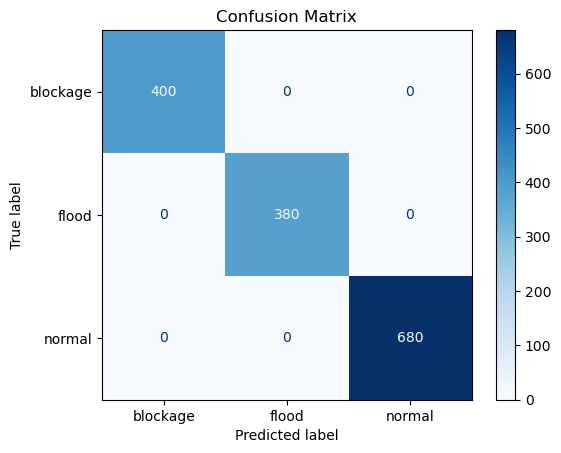

In [29]:
cm=confusion_matrix(

    y_test,

    y_pred

)

disp=ConfusionMatrixDisplay(

    confusion_matrix=cm,

    display_labels=encoder.classes_

)

disp.plot(

    cmap="Blues"

)

plt.title(

    "Confusion Matrix"

)

plt.show()

In [30]:
importance=pd.DataFrame({

    "Feature":FEATURES,

    "Importance":rf.feature_importances_

})

importance=importance.sort_values(

    by="Importance",

    ascending=False

)

print(importance)

                            Feature  Importance
2                        level_diff    0.225990
4                   rise_rate_node2    0.180574
3                   rise_rate_node1    0.157681
1                 water_level_node2    0.136654
0                 water_level_node1    0.103609
7  precipitationIntensity_next_hour    0.099091
5            precipitationIntensity    0.070573
6          precipitationProbability    0.025829


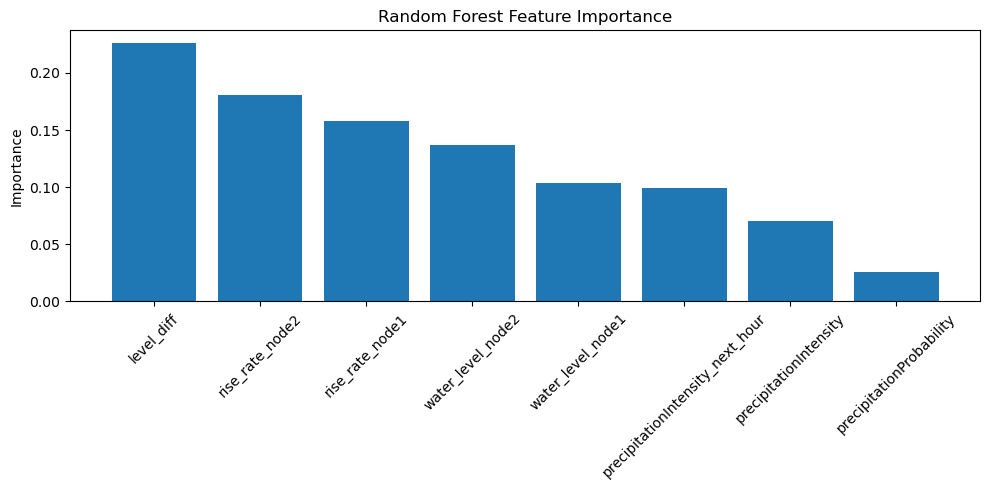

In [31]:
plt.figure(figsize=(10,5))

plt.bar(

    importance["Feature"],

    importance["Importance"]

)

plt.xticks(rotation=45)

plt.ylabel("Importance")

plt.title("Random Forest Feature Importance")

plt.tight_layout()

plt.show()

In [32]:
joblib.dump(

    rf,

    os.path.join(

        OUTPUT_DIR,

        "model.joblib"

    )

)

joblib.dump(

    encoder,

    os.path.join(

        OUTPUT_DIR,

        "encoder.joblib"

    )

)

print()

print("Model Saved")


Model Saved


In [33]:
# ===========================================
# Test Samples
# ===========================================

demo = pd.DataFrame([

    # --------------------------
    # NORMAL
    # --------------------------

    [
        6,
        6.5,
        6-6.5,
        0.8,
        0.7,
        1.5,
        10,
        2.0
    ],

    # --------------------------
    # FLOOD
    # --------------------------

    [
        31,
        30,
        31-30,
        12,
        11,
        45,
        95,
        60
    ],

    # --------------------------
    # BLOCKAGE
    # --------------------------

    [
        30,
        6,
        30-6,
        15,
        0.3,
        4,
        20,
        5
    ]

], columns=FEATURES)

In [34]:
prediction = rf.predict(demo)

prediction = encoder.inverse_transform(prediction)

print("Predictions")

for i,p in enumerate(prediction):

    print("Sample",i+1,"->",p)

Predictions
Sample 1 -> normal
Sample 2 -> flood
Sample 3 -> blockage


In [35]:
probabilities = rf.predict_proba(demo)

classes = encoder.classes_

for i in range(len(demo)):

    print("="*50)

    print("Sample",i+1)

    for cls,prob in zip(classes,probabilities[i]):

        print(f"{cls:12s}: {prob*100:.2f}%")

    print()

Sample 1
blockage    : 0.00%
flood       : 0.00%
normal      : 100.00%

Sample 2
blockage    : 0.00%
flood       : 100.00%
normal      : 0.00%

Sample 3
blockage    : 99.77%
flood       : 0.00%
normal      : 0.23%



In [36]:
def predict_condition(

    water_level_node1,
    water_level_node2,
    rise_rate_node1,
    rise_rate_node2,
    precipitationIntensity,
    precipitationProbability,
    precipitationIntensity_next_hour

):

    level_diff = water_level_node1-water_level_node2

    sample = pd.DataFrame([[

        water_level_node1,
        water_level_node2,
        level_diff,
        rise_rate_node1,
        rise_rate_node2,
        precipitationIntensity,
        precipitationProbability,
        precipitationIntensity_next_hour

    ]],columns=FEATURES)

    prediction = encoder.inverse_transform(

        rf.predict(sample)

    )[0]

    probs = rf.predict_proba(sample)[0]

    probability = dict(

        zip(

            encoder.classes_,

            probs

        )

    )

    return {

        "prediction":prediction,

        "flood_probability":

            round(

                probability["flood"]*100,

                2

            ),

        "blockage_probability":

            round(

                probability["blockage"]*100,

                2

            ),

        "normal_probability":

            round(

                probability["normal"]*100,

                2

            )

    }

In [37]:
result = predict_condition(

    water_level_node1=30,

    water_level_node2=28,

    rise_rate_node1=11,

    rise_rate_node2=10,

    precipitationIntensity=50,

    precipitationProbability=95,

    precipitationIntensity_next_hour=60

)

print(result)


{'prediction': 'flood', 'flood_probability': np.float64(99.76), 'blockage_probability': np.float64(0.24), 'normal_probability': np.float64(0.0)}
